In [ ]:
### Use the data in the knn example
from ml_lib import *
# features_in_mins, labels = read_labelled_data('labelled_in_mins.csv')
features, labels = read_labelled_data('labelled.csv')
plot_labelled_data(features, labels)

In [ ]:
import numpy as np

from ml_lib import *
np_features = np.loadtxt("labelled.csv",delimiter=",",usecols=(0,1))
np_labels= np.loadtxt("labelled.csv",delimiter=",",dtype=str,usecols=(-1,))

plot_data(np_features)

## k-Means

As an example of unsupervised learning, we will learn about the **k-Means** method for clustering unlabelled data points. 
**Clustering** is the process of grouping similar data points together based on their features. However, unlike the predefined labels in kNN and supervised learning, the groupings in k-Means and unsupervised learning are “discovered” by the algorithm and thus not predefined or named.

For example, let us use the data from the kNN section as unlabelled data by discarding the labels.

In [ ]:
del labels

The following figure plots this data on a graph with song length on the x-axis and song tempo on the y-axis.

In [ ]:
plot_data(features)

## Description of Algorithm

To perform k-Means clustering, we perform the following steps:

1. Choose k points to be the initial centroids of the k clusters. (The definition of "centroid" will be given later.) There are many possible initial assignments, but the simplest is to pick k data points at random. Like k in kNN, the k in k-Means is a hyperparameter that is chosen to control how the ML algorithm works. The following diagram illustrates this step using a simple example with 6 data points and k = 2.

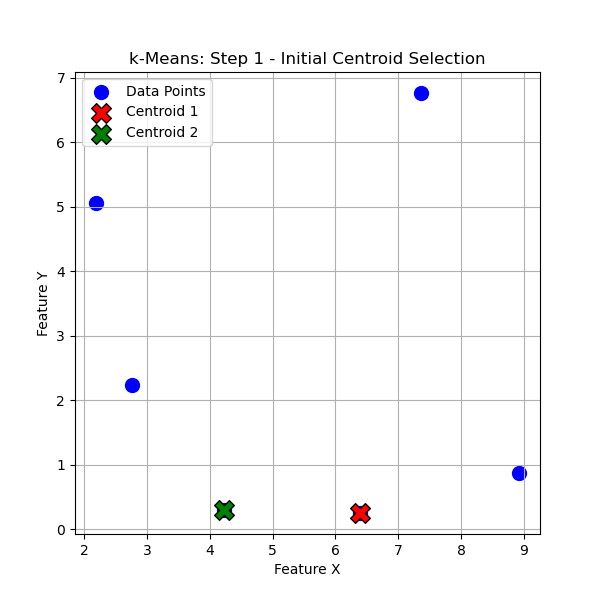

2. Assign data points to clusters using the nearest centroid by “distance”, using the same definition of distance from kNN. These data points are thus partition into two clusters.

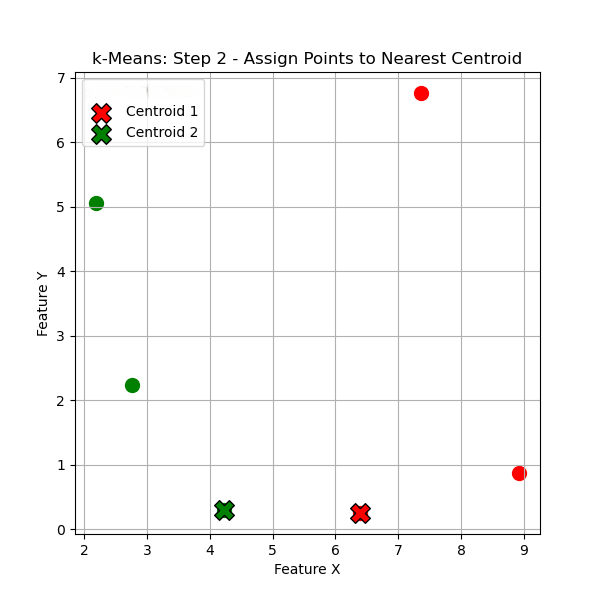

3. For each cluster, calculate the new average point or **centroid** of all the data points assigned to that cluster. As an example, for the task of grouping songs, the centroid of a cluster would be the point with x and y values equal to the average song length and average song tempo of all the data points assigned to that cluster.

    Let $C_i$ be the set of data points assigned to cluster $i$. Let $x(d)$ and $y(d)$ be the features of data point $d$. Then the centroid of cluster $i$ can be written as: 

    $$
    \textrm{Centroid of } C_i = \left(\frac{\sum_{d \in C_i} x(d)}{|C_i|}, \frac{\sum_{d \in C_i} y(d)}{|C_i|}\right)
    $$

    The following diagram illustrates how the centroid (shown as a star) of 4 data points is just the average of the 4 data points.
 
    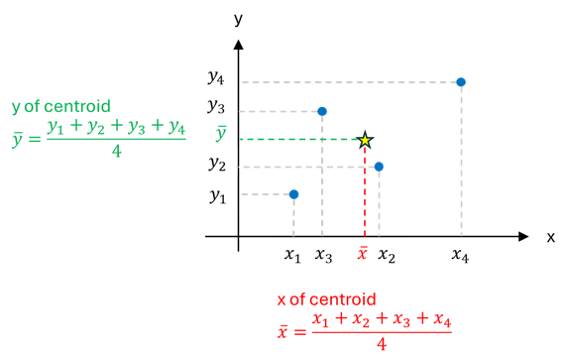<br>


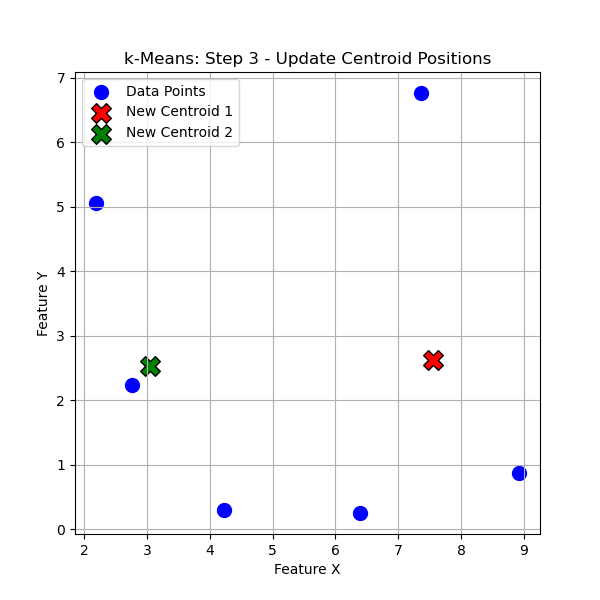


   
5. Repeat steps 2 and 3 until either the assignment of data points to clusters stops changing (i.e., **convergence**) or a maximum number of iterations is reached. The maximum number of iterations is yet another hyperparameter that is chosen to control how the ML algorithm works. 

6. Output the resulting assignment of data points to clusters.


## KMeans Plain Python Implementation


```mermaid
graph TD
    A[Step 1:Initialise k centroids] --> B
    B[Step 2:Assign each 
    datapoint to the nearest 
    centroid] --> C
    C(A cluster for each centroid 
      is made up of data points
      closest to it) --> D
    D[Step 4: Calculate k new 
    centroids for each cluster] --> E
    E{If all the new centroids == 
      original centroids 
      OR max iterations} -- No --> B
    E -- Yes --> F[ Exit ]
```

In [ ]:
# helper functions for k-means

def form_clusters(features, centroids):
    # form clusters from centroids
    
    cluster_members = { i:[] for i in range(len(centroids))}
    
    for point in features:
        # distance between point and each centroid
        distances = [distance_squared(point, centroids[i]) for i in range(len(centroids))]
        cluster_index = distances.index(min(distances)) # index of closest centroid
        cluster_members[cluster_index].append(point)
    return cluster_members

def find_centroids(cluster_members, centroids):
    new_centroids = []
    for i, points in cluster_members.items():
        if len(points) == 0: # if a centroid has no data points, keep the old centroid
            new_centroids.append(centroids[i])
            continue
        ## calculate new centoid for the cluster
        all_x = [ x for x,y in points]
        all_y = [ y for x,y in points]
        new_centroids.append( 
            ( sum(all_x)/len(all_x), sum(all_y)/len(all_y) )
        )
    return new_centroids

def plot_clusters(cluster_members, centroids):
    """Plot clusters and their centroids using different shapes and colours."""
    # Note: You do not need to understand how the following matplotlib code works.
    shapes = ['o', 's', '^', 'D', 'x']
    colours = ['red', 'blue', 'green', 'orange', 'purple']

    # Use hard-coded size values for this example.
    plt.figure(figsize=(6, 4.5))
    
    for i in range(len(centroids)):
        cluster_data = cluster_members[i]
        x = [p[0] for p in cluster_data]
        y = [p[1] for p in cluster_data]
        plt.scatter(x, y, c=colours[i % len(colours)], 
                    marker=shapes[i % len(shapes)], s=120, label=f'Cluster {i+1}')
        centroid = centroids[i]
        plt.scatter(centroid[0], centroid[1], c=colours[i % len(colours)], marker='X', s=120, edgecolors='white', linewidths=1.5)
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
## k means Step By Step for illustration
import random

random.seed(42)
k = 3 # centroids
n = 10 # max iterations

# Pick k data points from data set as initial centroids

# centroids = random.sample(features, k=k)  # uniques
centroids= random.choices(features,k=k) # with repetitions

cluster_members = { i:[] for i in range(len(centroids))}

for j in range(1,n+1): # maximum n iterations

    print("New centroids:")
    plot_clusters({ i:[] for i in range(len(centroids))}, centroids)

    print(f"Iteration {j} of Cluster")

    ## form clusters from centroids
    cluster_members = form_clusters(features,centroids)
    plot_clusters(cluster_members, centroids)


    ## compute new centroids from cluster
    new_centroids = find_centroids(cluster_members, centroids)
    
    if new_centroids == centroids:
        break
    else:
        centroids = new_centroids
else:
    print("Maximum of {n} iterations reached")

In [ ]:
## One-shot kmeans
import random
def k_means(k, features, max_iterations=10):

    centroids=random.choices(features,k=k)## it is ok to have duplicates
    for j in range(1,max_iterations+1): # maximum n iterations

        cluster_members = form_clusters(features, centroids)
        new_centroids = find_centroids(cluster_members, centroids)
 
        if new_centroids == centroids:
            break
        else:
            centroids = new_centroids
    return cluster_members, centroids

---

### KMeans Python Implementation using numpy


In [ ]:
# helper functions for k-means

def plot_clusters(cluster_members, centroids):
    """Plot clusters and their centroids using different shapes and colours."""
    # Note: You do not need to understand how the following matplotlib code works.
    shapes = ['o', 's', '^', 'D', 'x']
    colours = ['red', 'blue', 'green', 'orange', 'purple']

    # Use hard-coded size values for this example.
    plt.figure(figsize=(6, 4.5))
    
    for i in range(len(centroids)):
        cluster_data = cluster_members[i]
        x = [p[0] for p in cluster_data]
        y = [p[1] for p in cluster_data]
        plt.scatter(x, y, c=colours[i % len(colours)], 
                    marker=shapes[i % len(shapes)], s=120, label=f'Cluster {i+1}')
        centroid = centroids[i]
        plt.scatter(centroid[0], centroid[1], c=colours[i % len(colours)], marker='X', s=120, edgecolors='white', linewidths=1.5)
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
import numpy as np
def np_form_clusters(features:np.ndarray, centroids:np.ndarray)->dict[int:list[np.ndarray]]:
    # form clusters from centroids
    
    # clusters are labelled by the index of the centroid they are closest to
    cluster_members = { i:[] for i in range(len(centroids))} 
    for feature in features:
        cluster_members[
            np.argmin(np.sum(np.square(feature - centroids),axis=1))

        ].append(feature)

    return cluster_members
    

In [ ]:
np_centroids = np_features[np.random.choice(np_features.shape[0], size=3, replace=False)]
# centroids[None, :, :].shape

In [ ]:
def np_find_centroids(cluster_members:dict, centroids:np.ndarray)->np.ndarray:
    return np.array(
    [ 
        np.array(
                (np.mean(np.array(points)[:,0]), # points is a list
                 np.mean(np.array(points)[:,1])
                )
        )
        for i, points in cluster_members.items()
    ]
)

In [ ]:
## k means plot for every iterations for illustration
import random

np.random.seed(42)
k = 3 # centroids
n = 10 # max iterations

# Pick k data points from data set as initial centroids
np_centroids = np_features[np.random.choice(np_features.shape[0], size=k, replace=False)]

cluster_members = { i:[] for i in range(len(centroids))}

for j in range(1,n+1): # maximum n iterations

    print("New centroids:")
    plot_clusters({ i:[] for i in range(len(np_centroids))}, np_centroids)

    print(f"Iteration {j} of Cluster")

    ## form clusters from centroids
    cluster_members = np_form_clusters(np_features,np_centroids)
    plot_clusters(cluster_members, np_centroids)

    ## compute new centroids from cluster
    new_centroids = np_find_centroids(cluster_members, np_centroids)
    
    if np.allclose(new_centroids,np_centroids):
        break
    else:
        np_centroids = new_centroids
else:
    print(f"Maximum of {n} iterations reached")

In [ ]:
## One-shot kmeans
import random
def np_k_means(k, features, max_iterations=10):

    np.random.seed(42)
    np_centroids = features[np.random.choice(features.shape[0], size=k, replace=False)]
    for j in range(1,max_iterations+1): # maximum n iterations

        cluster_members = form_clusters(features, np_centroids)
        new_centroids = find_centroids(cluster_members, np_centroids)
 
        if np.allclose(new_centroids,np_centroids):
            break
        else:
            np_centroids = new_centroids
    return cluster_members, np_centroids

---

<div class="alert alert-block">
<u>Questoins </u>

- Can you conclude that clusters produced by k-Means always correspond to song genres? Why or why not?

- Predict the resulting clustering with k = 2. Run the program to check if you are correct.

- In the above program, how are ties for the nearest centroid resolved? Is it deterministic? If not, how can it be made deterministic?

</div>

## Effect of Initial Assignment

How quickly k-Means converges and the quality of the clustering depends greatly on the initial choice of centroids in Step 1.

Using a random selection of data points can cause problems as the initial centroids might end up bunched together or land on isolated outliers that are far away from everything else. These unfavourable starting conditions often produce low-quality clusters that don't reflect meaningful patterns in the dataset.

To mitigate the problems with random initial centroids, a common technique is to run the k-Means algorithm multiple times with different random initial centroids, then pick the highest quality clustering.

<div class="alert alert-block alert-success">

### <u>K-means++</u>

"K-means++" is a smarter way to choose the initial choice of centroids. After choosing the first centroid at random, each new centroid is chosen with probability proportional to distance squared. This helps to spread out the initial centroids, which usually leads to better final clusters and helps the algorithm finish faster.

</div>

## Evaluating Clustering Quality (Inertia)

The quality of a clustering can be measured by how tightly packed the clusters are. This is done by calculating the inertia or sum of squared distances between each data point and its nearest cluster centroid. Lower inertia values indicate better clustering as data points are closer to their centroids.

Let $C_i$ be the set of data points assigned to cluster $i$ with centroid $(\bar{x_i},\bar{y_i})$. Let $x(d)$ and $y(d)$ be the features of data point $d$. Then the inertia can be written as: 

$$
\textrm{Inertia} = \sum_{i=1}^k \sum_{d \in C_i} \left[\left(x(d)-\bar{x_i}\right)^2 + \left(y(d)-\bar{y_i}\right)^2\right]
$$


In [ ]:
def compute_inertia(cluster_members, centroids):
    """Computes the inertia of the provided clustering."""
    inertia = 0
    for i in range(len(centroids)):
        inertia += sum([ distance_squared(point, centroids[i]) for point in cluster_members[i] ])
    return inertia
    
# compute_inertia(cluster_members, centroids)

In [ ]:
cluster_members, centroids = k_means(3,features)
plot_clusters(cluster_members, centroids)
print(compute_inertia(cluster_members, centroids))

In [ ]:
def np_compute_inertia(cluster_members, centroids):
    """Computes the inertia of the provided clustering."""
    return sum( # sum all the clusters outer sigma
        [ 
            np.sum(# sum for each cluster, inner sigma
                np.sum(np.square(np.array(cluster_members[i]) - centroids[i]),axis=1) # sum square distances for all the features [..+..]
            ) 
            for i in range(len(centroids)) 
        ]
    )
            
np_compute_inertia(cluster_members, np_centroids)

In [ ]:
cluster_members, centroids = np_k_means(3,np_features)
plot_clusters(cluster_members, centroids)
print(np_compute_inertia(cluster_members, centroids))

<div class="alert">
    
### Question

Define a new function `kmeans_n_inits()` that accepts a new parameter `n_inits`. It should repeat k-Means `n_inits` times with different points chosen as the initial centroids and return the resulting clustering with the lowest inertia. (Use `compute_inertia()` from the previous question.)

</div>

In [ ]:
## Code

def kmeans_n_inits(k, data, max_iter, n_inits):

   archive = []
   for _ in range(n_inits):
      cc = k_means(k, data,max_iter)
      archive.append((*cc,compute_inertia(*cc)))
   return min(archive, key = lambda x: x[-1])

clusters,centroids,inertia = kmeans_n_inits(3, features, 10, 20)
print(f"Inertia:{inertia}")
plot_clusters(clusters, centroids)



In [ ]:
def np_kmeans_n_inits(k, data, max_iter, n_inits):

   archive = []
   for _ in range(n_inits):
      cc = k_means(k, data,max_iter)
      archive.append((*cc,compute_inertia(*cc)))
   return min(archive, key = lambda x: x[-1])

clusters,centroids,inertia = np_kmeans_n_inits(3, np_features, 10, 20)
print(f"Inertia:{inertia}")
plot_clusters(clusters, centroids)

